# E0 · Calibrate the simulator
*Step 1 of network-spectral-predictor · pendulums on springs · actual = generated world, nominal = prediction*

Every later experiment measures the model against this simulator, so the simulator is checked first.

**Where we're at.** Step 1, rung 1 (small swings). The plan's math has had a cursory review; this is the first code that runs.

**Where the system is after the last experiments.** Only scratch checks so far: the closed forms hold, and the one-hop model misses a two-hop term of relative size κλΔt²/6.

**Where we want it.** A ground truth trusted to ten times below every model deviation we will report.

**How this set moves it.** Checks velocity Verlet against the exact step for small swings, and against itself at 4× the substeps for large swings, which have no exact step.

In [1]:
%config InlineBackend.figure_format = 'retina'
import sys
from pathlib import Path
import numpy as np
from IPython.display import display
STUDY = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(STUDY))
import figures as F
from nsp import config, graphs, viz, world as W
F.setup()
cfg = F.cfg("e0")
world = config.world_from(cfg)
p = cfg["e0"]

In [2]:
F.ledger("e0")

**Configuration ledger**

| Setting | Value | Meaning |
| --- | --- | --- |
| `world.omega0` | 2.0 | a lone pendulum's frequency (rad/s) |
| `world.kappa` | 1.0 | spring stiffness ÷ inertia (1/s²) |
| `world.dt` | 0.05 | sampling step (s) |
| `world.d` | 1 | position coordinates per body (1 = planar) |
| `run.seeds` | [0, 1, 2] | seeds run (kept low on purpose) |
| `graph` | path | how the springs are wired |
| `n` | 3 | number of bodies |
| `amplitude` | 0.1 | starting swing size (rad) |
| `large_amplitude` | 2.0 | starting swing size, rung 2 (rad) |
| `samples` | 2000 | steps simulated |
| `substeps` | 50 | Verlet substeps per sample |
| `reference_substeps` | 200 | reference substeps |
| `trajectories` | 4 | trajectories per run |
| `player_steps` | 400 | steps shown in the player |

## The question

Small swings have an exact step; large swings (where $\sin\theta$ matters) only have an integrator:

$$\underbrace{x(t+1)}_{\text{actual, small swings}} = \underbrace{e^{A\Delta t}}_{\text{exact step}}\,x(t), \qquad A = \underbrace{I_n\otimes A_0}_{\text{each body}} - \underbrace{\kappa\,L(g)\otimes E}_{\text{springs}}$$

Here the integrator is under test, so it plays the **nominal** role and the exact step (or a 4× finer integrator) the **actual** one.

**Prediction.** Verlet with 50 substeps ($h = 1$ ms) has a phase error per sample of order $(\omega h)^3$ and a bounded energy error of order $(\omega h)^2$: parts per million.
**Pass if** the deviation at 10 s is under $10^{-4}$ of the swing, ten times below the smallest model deviation reported (about $10^{-3}$).

In [3]:
runs = F.ensure_results("e0")

e0: 3 seeds loaded (code fb79448, run 2026-11-25T20:28:47+00:00)


## The world

Three pendulums in a line, joined by springs. Small swings move as a sum of modes, one per graph frequency $\lambda_k$ (an eigenvalue of the Laplacian $L$), each a lone pendulum stiffened by $\kappa\lambda_k$:

$$\omega_k = \sqrt{\omega_0^2 + \kappa\lambda_k}$$

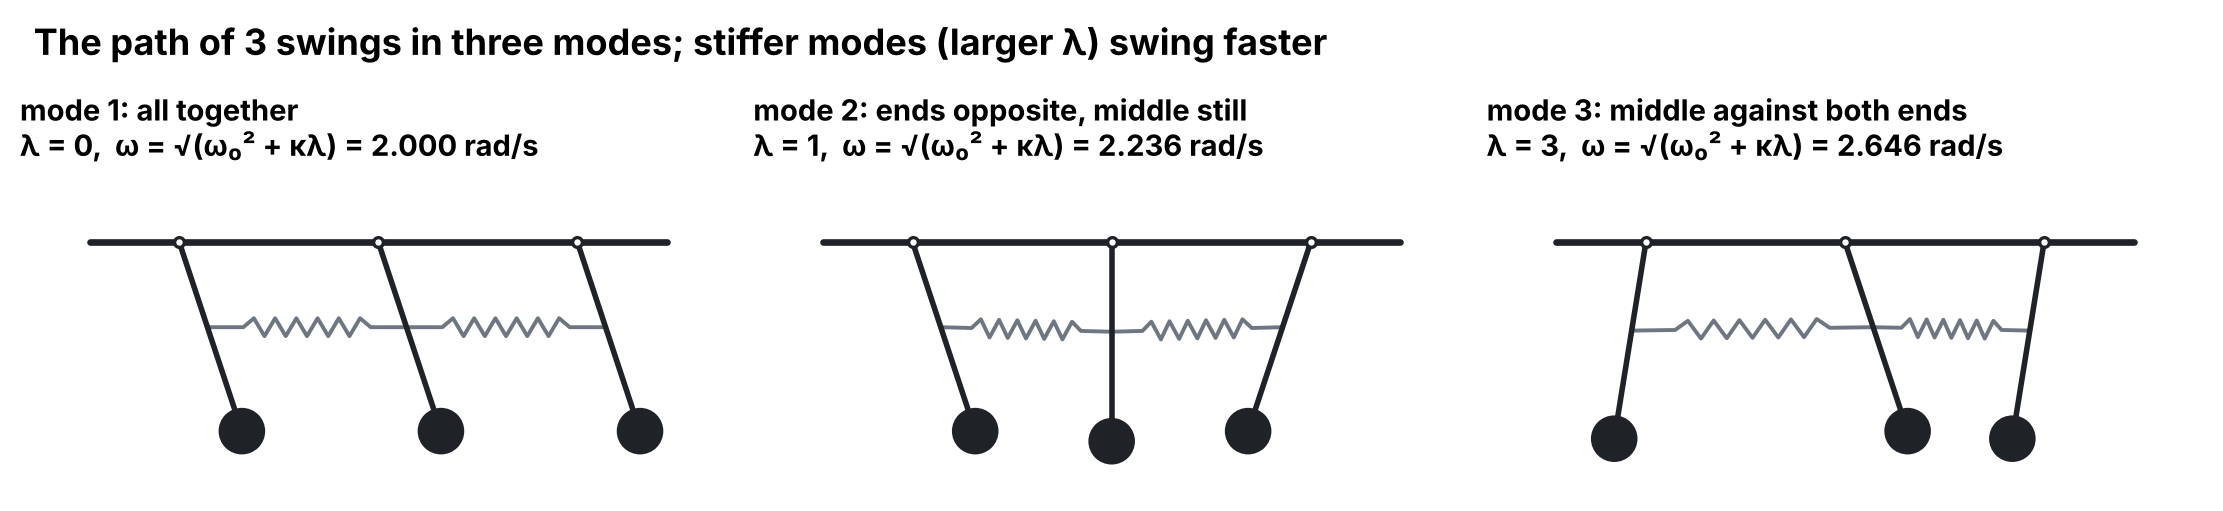

In [4]:
F.e0_modes(world, runs[0]);

## Nominal vs actual

Press **Play** to watch at real speed, or drag the slider. Actual bobs are filled, nominal bobs are hollow, and the whisker between them is the deviation, magnified (pick the factor) and coloured against the tolerance, like a CMM deviation plot. The trace underneath is the largest deviation over time. At ×1 the two worlds coincide exactly; turn the magnification up to see any deviation at all.

In [5]:
a = runs[0]["arrays"]
display(viz.player(a["theta_exact"], a["theta_verlet"], graphs.path(3), dt=world.dt, tol=1e-4 * p["amplitude"],
                   title="Small swings, 20 s: Verlet (nominal) against the exact step (actual)",
                   subtitle="Tolerance: 10⁻⁴ of the 0.1 rad swing."))
display(viz.player(a["theta_large_ref"], a["theta_large"], graphs.path(3), dt=world.dt,
                   tol=1e-4 * p["large_amplitude"], title="Released from up to 2 rad: 50 substeps (nominal) against 200 (actual)",
                   subtitle="Large swings have no exact step, so the reference is the same integrator, 4× finer."))

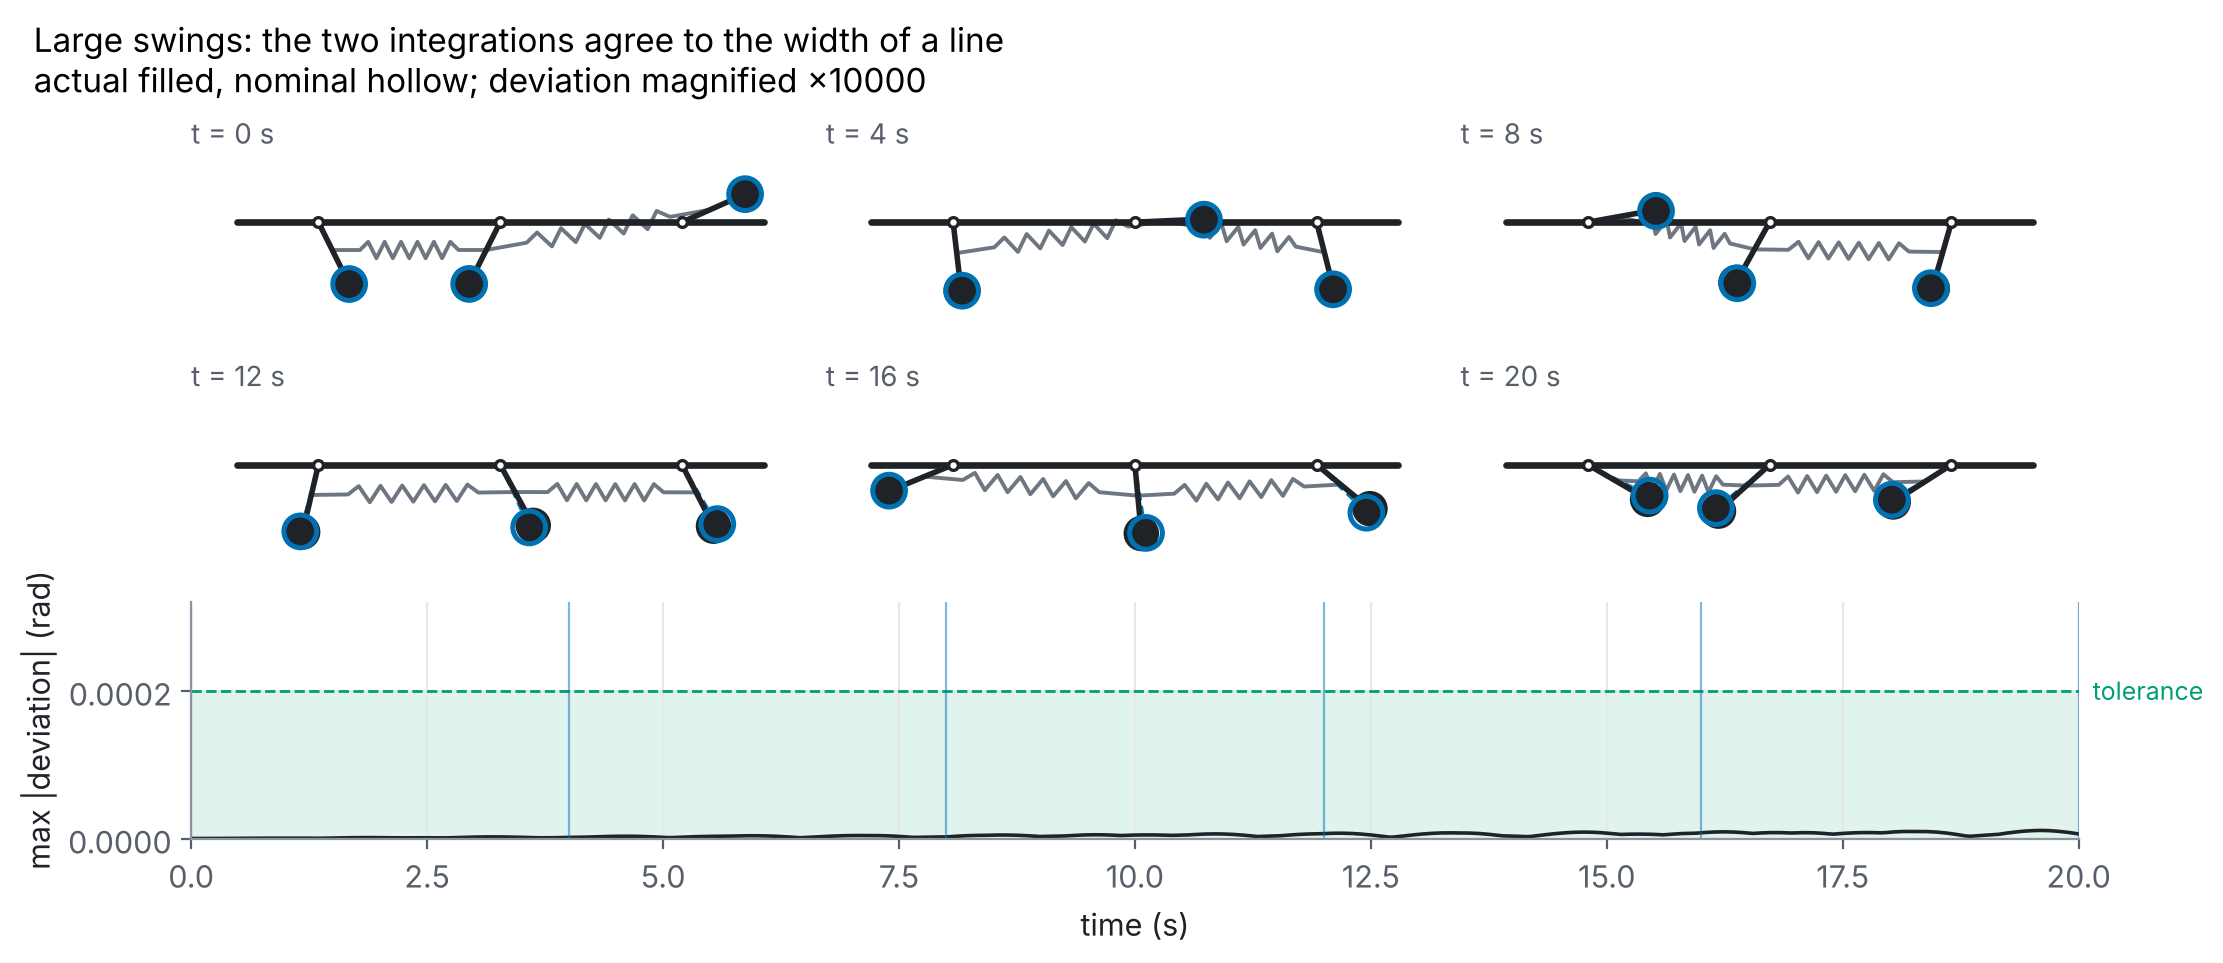

In [6]:
viz.film_strip(a["theta_large_ref"], a["theta_large"], graphs.path(3), dt=world.dt, tol=1e-4 * p["large_amplitude"],
               title="Large swings: the two integrations agree to the width of a line");

## Deviation and energy over 100 s

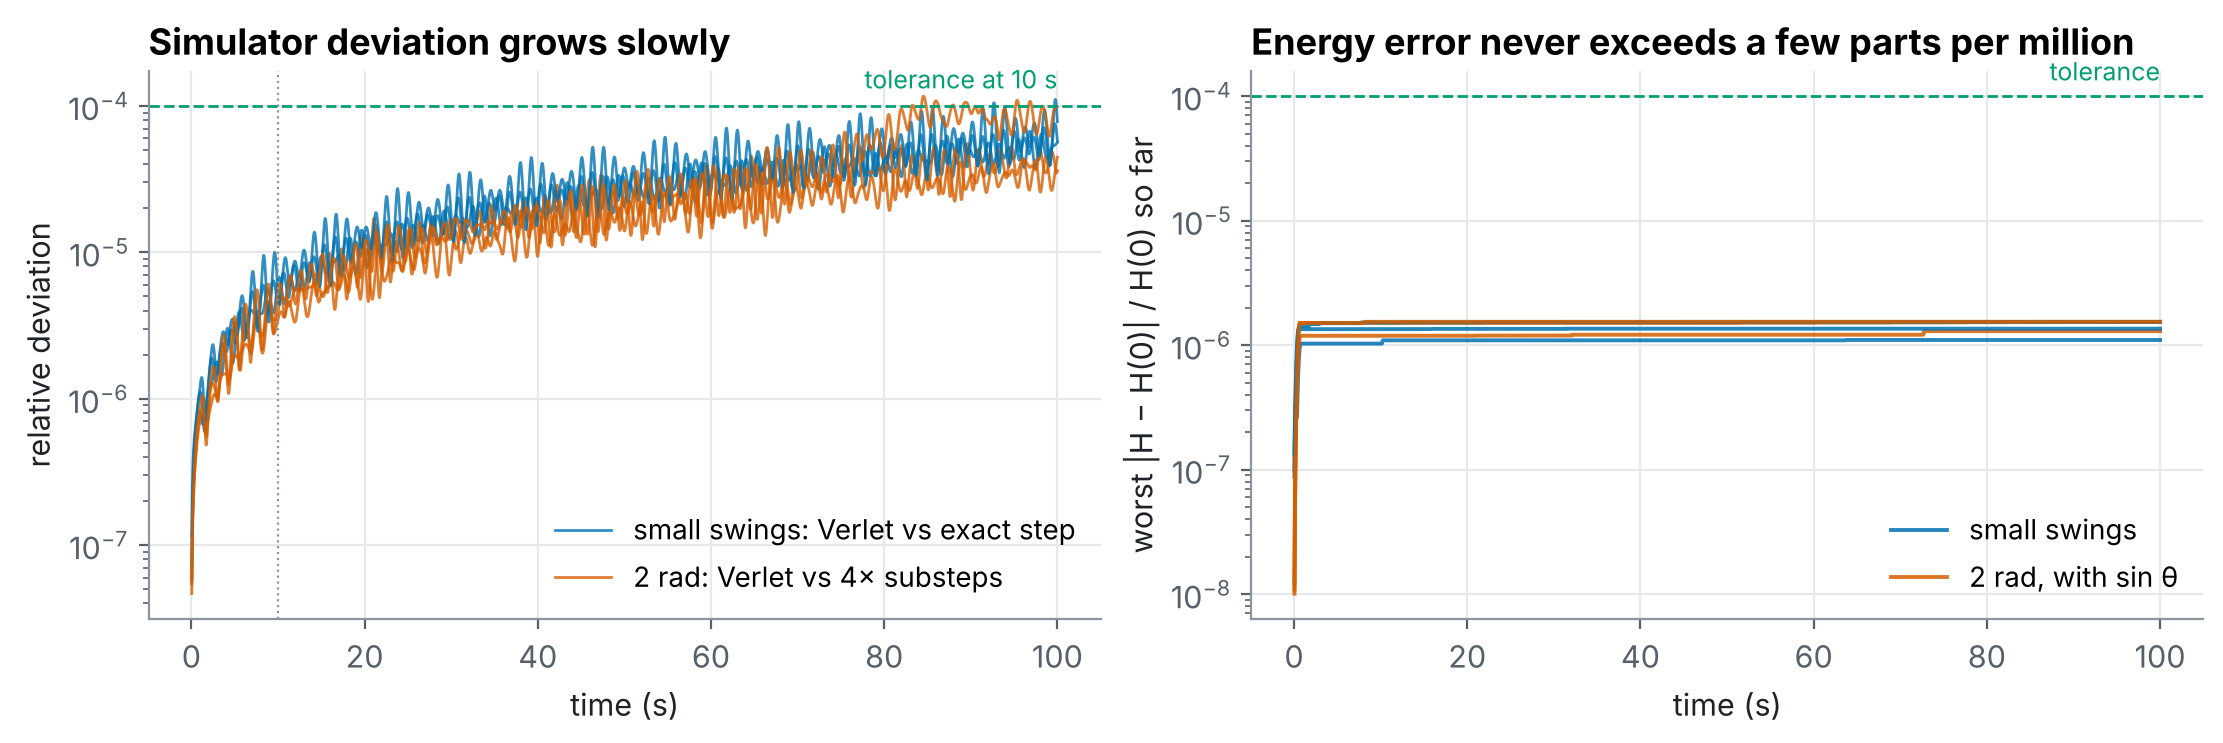

In [7]:
F.e0_error_growth(runs, world);

In [8]:
m = [r["metrics"] for r in runs]
F.say(f"At 10 s the simulator deviates by {F.spread([x['error_10s'] for x in m])} of the swing for small swings and "
      f"{F.spread([x['error_10s_large'] for x in m])} at 2 rad (mean, then min to max over seeds). Energy drifts by at "
      f"most {viz.fmt(max(x['energy_drift_small'] for x in m))} and {viz.fmt(max(x['energy_drift_large'] for x in m))}. "
      "Any deviation above 10⁻⁴ in later experiments therefore belongs to the model, not the simulator.")

> **Finding.** At 10 s the simulator deviates by 5.37 × 10⁻⁶ (4.44 × 10⁻⁶ to 6.41 × 10⁻⁶) of the swing for small swings and 4.30 × 10⁻⁶ (3.47 × 10⁻⁶ to 5.56 × 10⁻⁶) at 2 rad (mean, then min to max over seeds). Energy drifts by at most 1.53 × 10⁻⁶ and 1.54 × 10⁻⁶. Any deviation above 10⁻⁴ in later experiments therefore belongs to the model, not the simulator.

## Inspection report

In [9]:
mean = lambda k: float(np.mean([x[k] for x in m]))
viz.inspection_report([
    {"characteristic": "Deviation at 10 s, small swings (fraction of swing)", "deviation": mean("error_10s"), "tolerance": 1e-4},
    {"characteristic": "Deviation at 10 s, 2 rad (fraction of swing)", "deviation": mean("error_10s_large"), "tolerance": 1e-4},
    {"characteristic": "Deviation at 100 s, small swings", "deviation": mean("error_end"), "tolerance": 1e-3},
    {"characteristic": "Energy drift over 100 s, small swings", "deviation": mean("energy_drift_small"), "tolerance": 1e-4},
    {"characteristic": "Energy drift over 100 s, 2 rad", "deviation": mean("energy_drift_large"), "tolerance": 1e-4},
])

**Inspection report**

| Characteristic | Nominal (predicted) | Actual (generated) | Deviation | Tolerance | Status |
| --- | --- | --- | --- | --- | --- |
| Deviation at 10 s, small swings (fraction of swing) | — | — | 5.373 × 10⁻⁶ | ±1.000 × 10⁻⁴ | ✓ **in** |
| Deviation at 10 s, 2 rad (fraction of swing) | — | — | 4.302 × 10⁻⁶ | ±1.000 × 10⁻⁴ | ✓ **in** |
| Deviation at 100 s, small swings | — | — | 6.395 × 10⁻⁵ | ±0.001 | ✓ **in** |
| Energy drift over 100 s, small swings | — | — | 1.329 × 10⁻⁶ | ±1.000 × 10⁻⁴ | ✓ **in** |
| Energy drift over 100 s, 2 rad | — | — | 1.456 × 10⁻⁶ | ±1.000 × 10⁻⁴ | ✓ **in** |

## Log

In [10]:
F.log(runs)

| Seed | Code version | Run at (UTC) | Python | NumPy | SciPy |
| --- | --- | --- | --- | --- | --- |
| 0 | `fb79448` | 2026-11-25T20:28:47+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 1 | `fb79448` | 2026-11-25T20:28:46+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 2 | `fb79448` | 2026-11-25T20:28:51+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |